### **Introducción a Pytorch**

En este capítulo construiremos una red neuronal usando pythorch. Dado que conozco bien el fundamento teórico de una red neuronal el objetivo principal será aprender a usar pytorch y no desarrollaré en profundidad los fundamentos teóricos por una cuestion de tiempo. La referencia principal sera la documentación oficial de pytorch en este caso.

In [10]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2

import matplotlib.pyplot as plt

Importaremos un dataset integrado en pytorch en este caso. En el proximo proyecto deberemos construir nuestro propio dataset a partir de una simulacion númerica.

In [11]:
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    #transformo la imagen a tensor y la normalizo
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

Visualizamos brevemente algunos de los elementos de nuestro dataset. Son imagenes de 28x28 en escala de grises de articulos de ropa

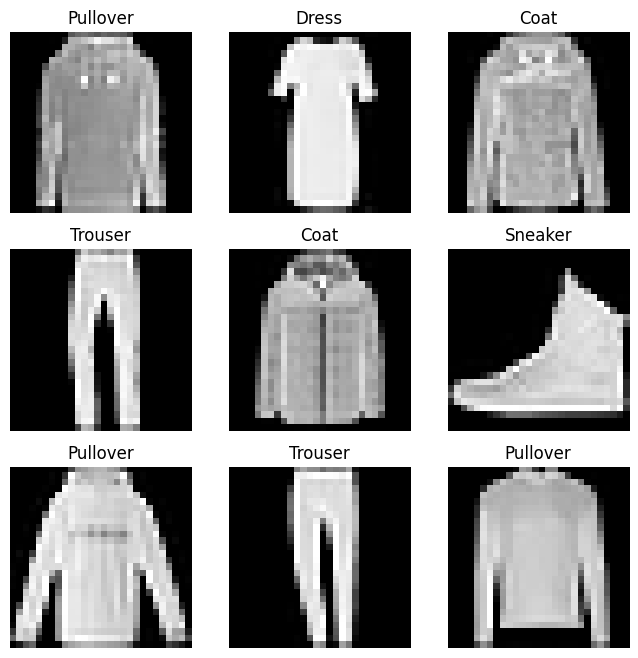

In [12]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

Para trabajar de mejor manera no usaremos el dataset crudo sino que instanciaremos un DataLoader. Lo que hace esto es darnos una manera de pasarle los datos a nuestros algoritmos de manera mas organizada y eficiente. Lo que haremos es separar nuestros datos en batches. De esta forma en vez de pasarle los ejemplos de entrenaimento y test uno a uno a la red se los pasaremos agrupados en batches de 64 ejemplos de forma que aprovechando la paralelizacion el proceso será mucho mas rápido y eficiente. Tambien nos permite reorganizar todo el dataset cada vez que hayamos iterado a traves de el completamente, esto reducirá el overfitting.

In [13]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

La red nueronal la construiremos como una clase que hereda de nn.Module que es una clase de pytorch que simplifica mucho la creacion y manetenimiento del modelo. En __ init __ definimos las arquitectura del modelo y debemos definir tambien una funcion forward a la que se llamara implicitamente siempre que queramos hacer una prediccion.  
Si quisieramos incluir una funcion de activacio o una capa personalizada se puede hacer perfectamente pero en general no hara falta.  

In [14]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

Por defecto todos los parametros de la red anterior se son aprendibles pero deseasemos fijar alguna capa o parametro concreto se puede hacer usando param.requires_grad = False

In [15]:
model = NeuralNetwork()

In [16]:
learning_rate = 1e-3
batch_size = 64
epochs = 5

Ahora tambien definiremos una funcion de perdida y un algoritmo de optimizacion para entrenar la red. En este caso tomaremos implementaciones de pytorch pero de nuevo en el proximo proyecto de cosntruccion de una PINN implementaremos nuestras porpias funciones y algoritmos personalizados.

In [17]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

A continuación construimos una función que entrena nuestra red actualizando los parametros para minimizar la función de pérdida de acuerdo a nuestro algoritmo de optimización. Notemos que las funciones que hemos usado antes estan preparadas para recibir batches y no solo ejemplos de netrenamiento sueltos por lo que podemos entrenar el modelo usando batches de forma mucho mas limpia.

In [18]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward() #calcula los gradiente de los parametros
        optimizer.step() #actualiza los parametros del modelo con los gradientes calculados
        optimizer.zero_grad() #reinicia a cero los gradientes de los parametros para la siguiente iteracion

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    #Es este caso no no interesan los gradiente y por eso se desactiva el calculo de los mismos
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item() #me devuelve un tensor y con .item() lo convierto a un numero
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [19]:
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, model, loss_fn, optimizer)
    test_loop(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.310348  [   64/60000]
loss: 2.289398  [ 6464/60000]
loss: 2.273834  [12864/60000]
loss: 2.255419  [19264/60000]
loss: 2.226947  [25664/60000]
loss: 2.215467  [32064/60000]
loss: 2.223346  [38464/60000]
loss: 2.216068  [44864/60000]
loss: 2.201827  [51264/60000]
loss: 2.168967  [57664/60000]
Test Error: 
 Accuracy: 44.9%, Avg loss: 2.158769 

Epoch 2
-------------------------------
loss: 2.175519  [   64/60000]
loss: 2.141114  [ 6464/60000]
loss: 2.122611  [12864/60000]
loss: 2.113468  [19264/60000]
loss: 2.107781  [25664/60000]
loss: 1.994838  [32064/60000]
loss: 2.016542  [38464/60000]
loss: 1.912411  [44864/60000]
loss: 1.932435  [51264/60000]
loss: 1.915679  [57664/60000]
Test Error: 
 Accuracy: 55.7%, Avg loss: 1.894348 

Epoch 3
-------------------------------
loss: 1.933165  [   64/60000]
loss: 1.848093  [ 6464/60000]
loss: 1.786156  [12864/60000]
loss: 1.743341  [19264/60000]
loss: 1.772095  [25664/60000]
loss: 1.699394  [32064/600